# Overlay a crop dataset on an environmental layer

Choose a crop and a static or TraCE layer. The layer is loaded over the crop file extent, which already includes the configured padding. Crop points are colored by time. Run the cells from top to bottom.

In [1]:
# Import plotting, array, and project data-loading tools.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add the project root so this notebook works when Jupyter starts in a subfolder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'processing' / 'load_layers.py').exists():
    PROJECT_ROOT = next((parent for parent in Path.cwd().parents if (parent / 'processing' / 'load_layers.py').exists()), Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import the same loaders used by the application.
from processing.load_layers import load_layer
from processing.load_data import load_data

In [2]:
# Choose one point dataset and one environmental layer to compare.
crop_name = 'wheat'
layer_name = 'prec'

# Use one degree-based resolution for every selected layer.
delta = 0.5

# Select the processed data folders used by the project.
CROP_DIRECTORY = PROJECT_ROOT / 'data' / 'processed' / 'crop'
LAYER_DIRECTORY = PROJECT_ROOT / 'data' / 'processed' / 'layers'

In [3]:
# Load crop observations and use the stored padded extents to select the layer window.
crop_data = load_data(crop_name, CROP_DIRECTORY)
year_extent = [crop_data['time'].min(), crop_data['time'].max()]  if layer_name in ['prec', 'temp' ] else None

latitude_extent = tuple(np.asarray(crop_data['lat_extent'], dtype=float))
longitude_extent = tuple(np.asarray(crop_data['lon_extent'], dtype=float))
layer_data = load_layer(
    layer_name,
    latitude_extent,
    longitude_extent,
    year_extent=year_extent,
    layer_directory=LAYER_DIRECTORY,
    delta=delta,
)

# Report the padded bounds and loaded shapes so mismatches are easy to spot.
print(f"Crop: {crop_name}; observations: {len(crop_data['lat']):,}")
print(f'Crop padded extent (degrees): latitude={latitude_extent}, longitude={longitude_extent}')
print(f"Layer: {layer_name}; grid shape={layer_data['data'].shape}")
print(f"Layer coordinate lengths: lat={len(layer_data['lat'])}, lon={len(layer_data['lon'])}")
if 'years' in layer_data:
    print(f"Layer years averaged: {layer_data['years'].min():g} to {layer_data['years'].max():g}")

Crop: wheat; observations: 908
Crop padded extent (degrees): latitude=(np.float64(7.2166999999999994), np.float64(64.35)), longitude=(np.float64(-14.82), np.float64(93.083905))
Layer: prec; grid shape=(115, 216)
Layer coordinate lengths: lat=115, lon=216
Layer years averaged: -10850 to -950.001


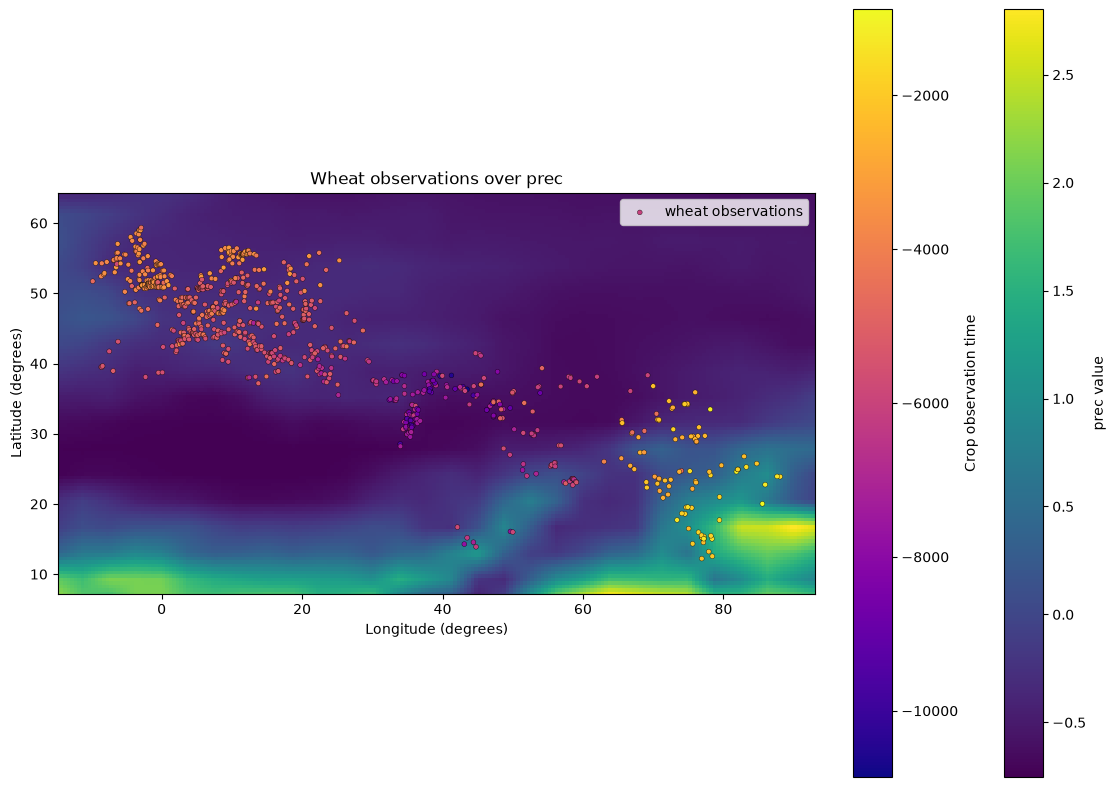

In [4]:
# Draw the environmental grid first, then overlay crop observations colored by their dates.
fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
mesh = ax.pcolormesh(
    layer_data['lon'],
    layer_data['lat'],
    np.ma.masked_invalid(layer_data['data']),
    shading='auto',
    cmap='viridis',
)
fig.colorbar(mesh, ax=ax, label=f'{layer_name} value')
points = ax.scatter(
    crop_data['lon'],
    crop_data['lat'],
    c=crop_data['time'],
    cmap='plasma',
    s=12,
    edgecolors='black',
    linewidths=0.25,
    label=f'{crop_name} observations',
)
fig.colorbar(points, ax=ax, label='Crop observation time')
ax.set_xlim(longitude_extent)
ax.set_ylim(latitude_extent)
ax.set_xlabel('Longitude (degrees)')
ax.set_ylabel('Latitude (degrees)')
ax.set_title(f'{crop_name.capitalize()} observations over {layer_name}')
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='best')
plt.show()

In [15]:
import matplotlib.pyplot as plt

# Import the estimator to load the processed crop and geography layers.
from diffusion_estimator import DiffusionEstimator

# Define a small, reproducible single-theta example for manual inspection.
crop_name = "wheat"
layer_names = ["prec", "sea"]
theta = np.array([-0.2506,2.3219,3.8416], dtype=float)
repetitions = 100
estimator = DiffusionEstimator(crop_name, layer_names)
speed = estimator.build_speed(theta)

# Calculate the averaged Monte Carlo field and the observed-data error.
arrival_times, mean_squared_error = estimator.calculate_simulation_times_and_error(
    speed,
    n_reps=repetitions,
    random_state=3,
)
print(f"Crop: {crop_name}")
print(f"Layers: {', '.join(layer_names)}")
print(f"Theta: {theta}")
print(f"Monte Carlo repetitions: {repetitions}")
print(f"Mean squared error: {mean_squared_error:.6f}")

Crop: wheat
Layers: prec, sea
Theta: [-0.2506  2.3219  3.8416]
Monte Carlo repetitions: 100
Mean squared error: 2070849.328106


In [16]:
np.sqrt(mean_squared_error)

np.float64(1439.0445886440514)